In [1]:
!pip install opencv_python

In [2]:
import cv2

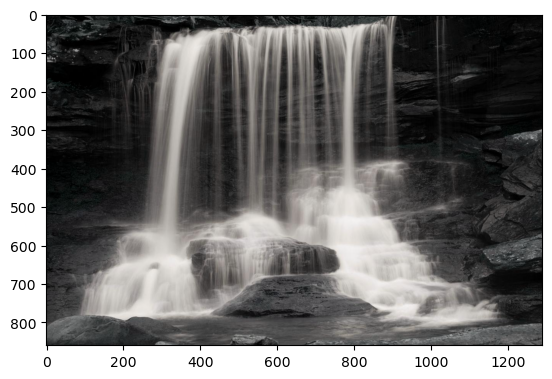

In [3]:
# Dark image : 
# converted to Gray
dark_img = cv2.imread('dark_waterfall.jpg')
import matplotlib.pyplot as plt
plt.imshow(dark_img)


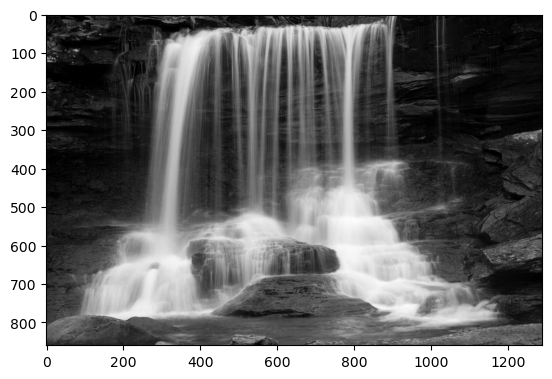

In [4]:
# original image
dark_img = cv2.cvtColor(dark_img,cv2.COLOR_BGR2GRAY)
plt.imshow(dark_img,cmap = 'gray')

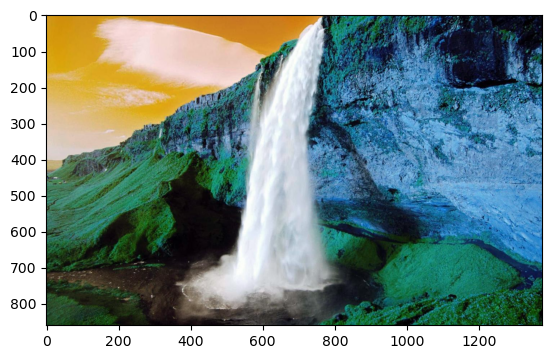

In [5]:
bright_img = cv2.imread('bright_waterfal.jpg')
plt.imshow(bright_img)


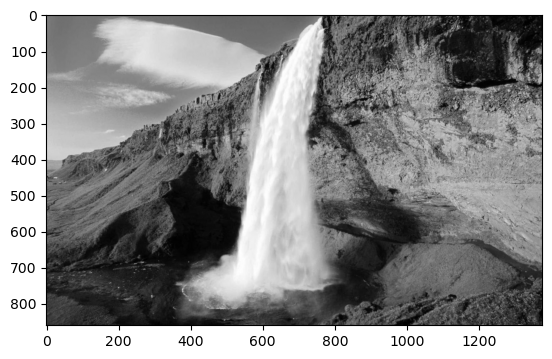

In [6]:
# Reference Image:
bright_img= cv2.cvtColor(bright_img,cv2.COLOR_BGR2GRAY)
plt.imshow(bright_img,cmap='gray')

Text(0.5, 1.0, 'Original Histogram(INPUT IMG)')

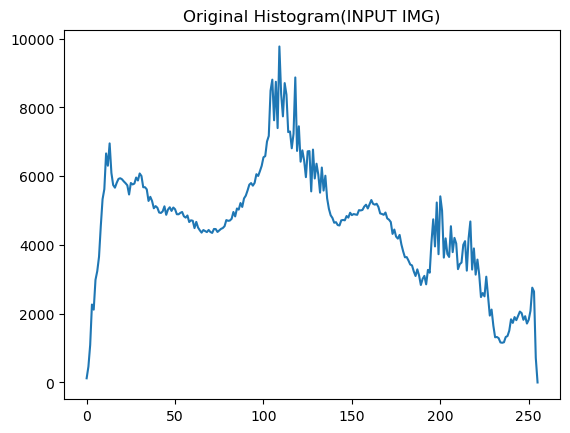

In [7]:
# Prinitng Histogram
original_hist = cv2.calcHist([bright_img],[0],None,[256],[0,255])
# Plot histogram
plt.plot(original_hist)
plt.title("Original Histogram(INPUT IMG)")

Text(0.5, 1.0, 'Equalized Histogram [Input img]')

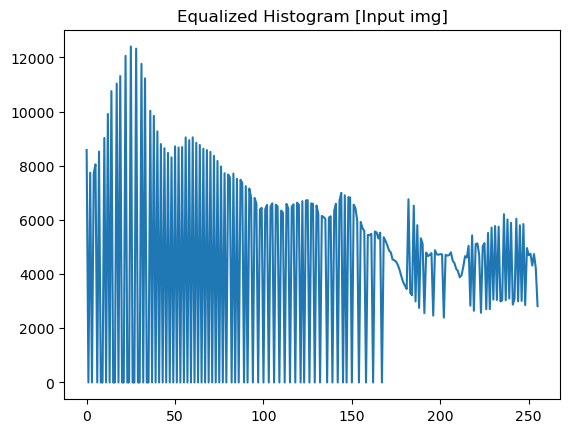

In [8]:
# Histogram Equalization
equalized_img = cv2.equalizeHist(dark_img)
equalized_hist = cv2.calcHist([equalized_img],[0],None,[256],[0,256])
plt.plot(equalized_hist)
plt.title("Equalized Histogram [Input img]")

Equalized image [dark]


Text(0.5, 1.0, 'Equalized Histogram[Dark]')

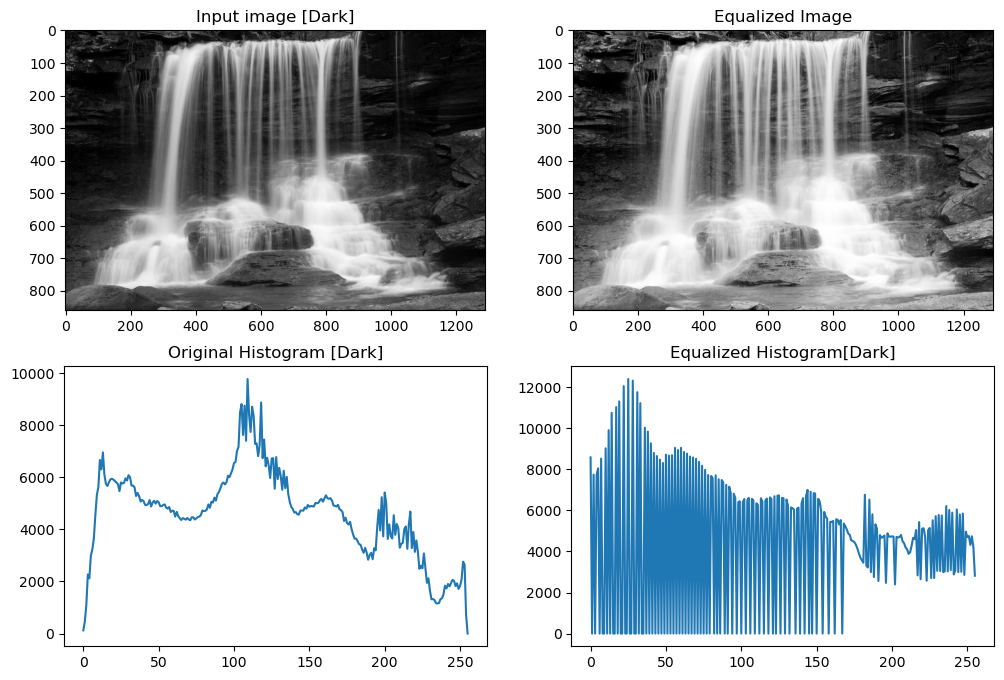

In [10]:
plt.figure(figsize=(12,8))
plt.subplot(2,2,1)
plt.imshow(dark_img,cmap='gray')
plt.title("Input image [Dark]")

plt.subplot(2,2,2)
plt.imshow(equalized_img,cmap='gray')
print("Equalized image [dark]")
plt.title("Equalized Image")

plt.subplot(2,2,3)
plt.plot(original_hist)
plt.title("Original Histogram [Dark]")

plt.subplot(2,2,4)
plt.plot(equalized_hist)
plt.title("Equalized Histogram[Dark]")

In [14]:
# Calculating Measures:
import numpy as np
from skimage.measure import shannon_entropy
def cal_measures(image):
    
    # Mean: Brighteness --> high mean --> more brightness
    #--. low mean --> less brightness
    mean = np.mean(image)
    
    # S.D: Spread of pixel values in image
    # more s.d --> spread over wider range
    sd = np.std(image)

    contrast = sd

    # Entropy
    entropy = shannon_entropy(image)

    return mean,sd,contrast,entropy

original_measure = cal_measures(dark_img)
equalized_measure = cal_measures(equalized_img)


In [15]:
# Printing values:
import pandas as pd
data = pd.DataFrame(
    {
        'Image': ['Original_Img ','Equalized_Img'],
        'Mean' : [original_measure[0],equalized_measure[0]],
        'SD' : [original_measure[1],equalized_measure[1]],
        'Contrast' : [original_measure[2],equalized_measure[2]],
        'Entopy' : [original_measure[3],equalized_measure[3]]
    }
)
print(round(data,2))
        

           Image   Mean     SD  Contrast  Entopy
0  Original_Img    83.2  65.45     65.45    7.67
1  Equalized_Img  127.2  73.90     73.90    7.43
